# Deep Learning Demo: XOR
## Jupyter Lab Version

Author: Andrew H. Fagg (andrewhfagg@gmail.com)

In [2]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
import os
import time

# Check out Jupyter Lab!
# Tensorflow 2.x way of doing things (if this doesn't work, then you have a very old version of tensorflow)
from tensorflow.keras.layers import InputLayer, Dense
from tensorflow.keras.models import Sequential

# Default plotting parameters
FONTSIZE = 18
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = FONTSIZE

2022-02-01 15:31:08.877862: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2022-02-01 15:31:08.877893: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [4]:
# Shell command to check GPU usage: nvidia-smi
# Execute if you do not want the GPU to be used:
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"


In [5]:
# GPU check
physical_devices = tf.config.list_physical_devices('GPU') 
n_physical_devices = len(physical_devices)
if(n_physical_devices > 0):
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
    print('We have %d GPUs\n'%n_physical_devices)
else:
    print('NO GPU')

NO GPU


In [13]:
def build_model(n_inputs, n_hidden, n_output, activation='elu', lrate=0.001):
    '''
    Build a simple dense model
    
    :param n_inputs: Number of input dimensions
    :param n_hidden: Number of units in the hidden layer
    :param n_output: Number of ouptut dimensions
    :param activation: Activation function to be used for hidden and output units
    :param lrate: Learning rate for Adam Optimizer
    '''
    # Simple sequential model
    model = Sequential();
    
    # Add layers to model
    model.add(
        InputLayer(input_shape=(n_inputs,))
    )
    model.add(
        Dense(n_hidden, use_bias=True, name="hidden", activation=activation)
    )
    model.add(
        Dense(n_output, use_bias=True, name="output", activation=activation)
    )
    
    # add an optimizer
    # Adam includes momentum and if gradient is flat, then, learning rate is increased!
    opt = tf.optimizers.Adam(learning_rate=lrate, 
                             beta_1=0.9, 
                             beta_2=0.999, 
                             epsilon=None, 
                             decay=0.0, 
                             amsgrad=False)
    # Compile and add solver
    model.compile(loss="mse", optimizer=opt)
    
    
    # Display the network
    print(model.summary())
    
    #
    return model

In [9]:
# Create training set: XOR
ins = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
outs = np.array([[0], [1], [1], [0]])

In [10]:
ins.shape

(4, 2)

In [11]:
outs.shape

(4, 1)

In [26]:
# Build our XOR network.  
# Note: sigmoid is a must for binary functions
model = build_model(ins.shape[1], 2, outs.shape[1], activation="sigmoid")
# None, 2 uses None as a placeholder for the number of instances/patterns.

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hidden (Dense)              (None, 2)                 6         
                                                                 
 output (Dense)              (None, 1)                 3         
                                                                 
Total params: 9
Trainable params: 9
Non-trainable params: 0
_________________________________________________________________
None


In [27]:
# Training
history = model.fit(x=ins, y=outs, epochs=400)

Epoch 1/400
1/1 [==============================] - 0s 340ms/step - loss: 0.2519
Epoch 2/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2519
Epoch 3/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2519
Epoch 4/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2518
Epoch 5/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2518
Epoch 6/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2518
Epoch 7/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2517
Epoch 8/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2517
Epoch 9/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2517
Epoch 10/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2517
Epoch 11/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2516
Epoch 12/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2516
Epoch 13/400
1/1 [==============================] - 0s 3ms/

1/1 [==============================] - 0s 5ms/step - loss: 0.2497
Epoch 104/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2497
Epoch 105/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2497
Epoch 106/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2497
Epoch 107/400
1/1 [==============================] - ETA: 0s - loss: 0.249 - 0s 4ms/step - loss: 0.2496
Epoch 108/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2496
Epoch 109/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2496
Epoch 110/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2496
Epoch 111/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2496
Epoch 112/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2495
Epoch 113/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2495
Epoch 114/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2495
Epoch 115/400
1/1 [===========

1/1 [==============================] - 0s 4ms/step - loss: 0.2477
Epoch 204/400
1/1 [==============================] - 0s 6ms/step - loss: 0.2477
Epoch 205/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2477
Epoch 206/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2476
Epoch 207/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2476
Epoch 208/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2476
Epoch 209/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2476
Epoch 210/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2476
Epoch 211/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2475
Epoch 212/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2475
Epoch 213/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2475
Epoch 214/400
1/1 [==============================] - 0s 6ms/step - loss: 0.2475
Epoch 215/400
1/1 [==============================] - 0

1/1 [==============================] - 0s 4ms/step - loss: 0.2454
Epoch 304/400
1/1 [==============================] - 0s 3ms/step - loss: 0.2454
Epoch 305/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2453
Epoch 306/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2453
Epoch 307/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2453
Epoch 308/400
1/1 [==============================] - ETA: 0s - loss: 0.245 - 0s 4ms/step - loss: 0.2453
Epoch 309/400
1/1 [==============================] - 0s 6ms/step - loss: 0.2452
Epoch 310/400
1/1 [==============================] - 0s 6ms/step - loss: 0.2452
Epoch 311/400
1/1 [==============================] - 0s 4ms/step - loss: 0.2452
Epoch 312/400
1/1 [==============================] - 0s 8ms/step - loss: 0.2452
Epoch 313/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2451
Epoch 314/400
1/1 [==============================] - 0s 5ms/step - loss: 0.2451
Epoch 315/400
1/1 [===========

Text(0.5, 0, 'epochs')

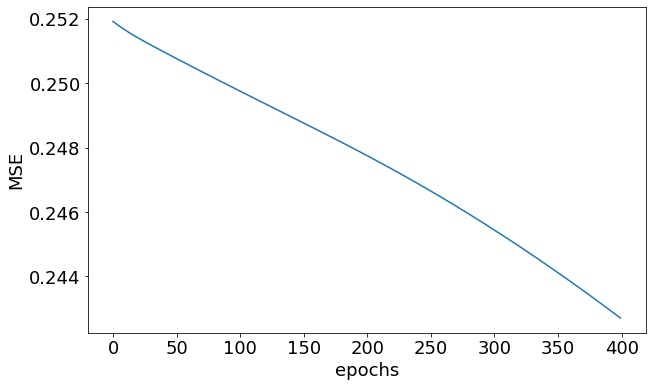

In [28]:
# Display
plt.plot(history.history['loss'])
plt.ylabel('MSE')
plt.xlabel('epochs')

In [29]:
model.predict(ins)

array([[0.4846926 ],
       [0.5248906 ],
       [0.50350094],
       [0.51335216]], dtype=float32)

## Training with Logging

In [ ]:
# Construct new model
model = 

# Set up a checkpoint callback that will be called with each epoch
checkpoint_cb = 

# Callback that will evaluate whether the gradient is essentially zero
early_stopping_cb = 


In [ ]:
# Note: faking validation data to get the checkpoints to work properly
history = 


In [ ]:
# Display
plt.plot(history.history['loss'])
plt.ylabel('MSE')
plt.xlabel('epochs')

In [ ]:
model.predict(ins)

## Adding Tensorboard

### Server
tensorboard --logdir=./my_logs --port=6006

In [ ]:
# Set directory where logs will be placed
root_logdir = "my_logs"

In [ ]:
# Create a log directory that corresponds to *this* specific instant
this_log_dir = os.path.join(root_logdir, "xor", time.strftime("_%Y_%m_%d_%H_%M_%S"))

# Create yet another model
model = 

# Log checkpoint
checkpoint_cb = 

# Early stopping checkpoint
early_stopping_cb = 

# TensorBoard checkpoint
tensorboard_cb = keras.callbacks.TensorBoard(this_log_dir)

In [ ]:
# Note: faking validation data to get the checkpoints to work properly
history = 


In [ ]:
model.predict(ins)